# 03 Season

## From 02

- NO₂ spans 7.6 to 26.3 µg/m³ across stations, PM2.5 8.2 to 13.6
- NO₂ has a strong daily cycle, PM2.5 almost none
- Weekend NO₂ falls 14 to 25 % citywide, PM2.5 under 4 %
- Fireworks flagged in 01, not excluded in 02

## Hypothesis

H2: both pollutants highest in winter, lowest in summer, at all stations

In [32]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

# One colour system across notebooks.
# Hue = pollutant. Blue/orange is CVD safe.
COLOUR = {"no2": "#4c72b0", "pm2": "#dd8452"}
PALE   = {"no2": "#b8c6de", "pm2": "#f0cab5"}
CMAP   = {"no2": "mako_r", "pm2": "flare"}

CURRENT = {"no2": 40, "pm2": 25}    # annual mean, in force 2025
LIMIT   = {"no2": 20, "pm2": 10}    # annual mean, EU 2030
WHO     = {"no2": 10, "pm2": 5}

# $_2$ renders the subscript. The plain ₂ character draws as a box in figures.
LABEL = {
    "no2": "NO$_2$ · mainly traffic exhaust · airways",
    "pm2": "PM2.5 · fine particles · heart and blood vessels",
}

NAME = {
    "mc010": "Amrumer Str., Wedding",
    "mc027": "Schichauweg, Marienfelde",
    "mc032": "Grunewald, Charlottenburg-Wilmersdorf",
    "mc042": "Nansenstr., Neukölln",
    "mc077": "Buch, Pankow",
    "mc085": "Friedrichshagen, Treptow-Köpenick",
    "mc117": "Schildhornstr., Steglitz",
    "mc124": "Mariendorfer Damm, Mariendorf",
    "mc144": "Silbersteinstr., Neukölln",
    "mc145": "Frohnau, Reinickendorf",
    "mc171": "Brückenstr., Mitte",
    "mc174": "Frankfurter Allee, Friedrichshain",
    "mc190": "Leipziger Str., Mitte",
    "mc221": "Karl-Marx-Str., Neukölln",
    "mc282": "Karlshorst, Lichtenberg",
}

TYPE = {
    "mc010": "background", "mc042": "background",
    "mc171": "background", "mc282": "background",
    "mc027": "suburb", "mc032": "suburb", "mc077": "suburb",
    "mc085": "suburb", "mc145": "suburb",
    "mc117": "traffic", "mc124": "traffic", "mc144": "traffic",
    "mc174": "traffic", "mc190": "traffic", "mc221": "traffic",
}

# Cleaned table from 01. Drops and fireworks flag already applied.
# CSV stores the offset as text, so parse to UTC then convert, as in 01.
ROOT = Path.cwd().parent
df = pd.read_csv(ROOT / "data" / "processed" / "hourly.csv")
df["datetime"] = pd.to_datetime(df["datetime"], utc=True).dt.tz_convert("Europe/Berlin")
df["fireworks"] = df["fireworks"].astype(bool)      # survives CSV as text otherwise

print(df.shape)

(236180, 7)


In [33]:
# Monthly mean per station, both pollutants.
mon = (df.groupby(["core", "station", df["datetime"].dt.month])["value"]
         .mean().rename("mean").reset_index()
         .rename(columns={"datetime": "month"}))

print(mon.groupby("core").size())      # 15 × 12 = 180, 12 × 12 = 144
mon.head()

core
no2    180
pm2    144
dtype: int64


,core,station,month,mean
0,no2,mc010,1,22.191375
1,no2,mc010,2,25.900149
2,no2,mc010,3,26.904184
3,no2,mc010,4,14.630042
4,no2,mc010,5,12.209960


In [34]:
# The flag covers 31 Dec 18:00 to 1 Jan 06:00, so it touches both January and
# December. Does excluding it change those months?
for m, name in [(1, "Jan"), (12, "Dec")]:
    sub = df[df["datetime"].dt.month == m]
    for core in ["no2", "pm2"]:
        g = sub[sub["core"] == core]
        print(name, core,
              "| with", round(g["value"].mean(), 2),
              "| without", round(g[~g["fireworks"]]["value"].mean(), 2))

Jan no2 | with 18.85 | without 18.88
Jan pm2 | with 11.47 | without 11.18
Dec no2 | with 18.56 | without 18.55
Dec pm2 | with 13.85 | without 13.66


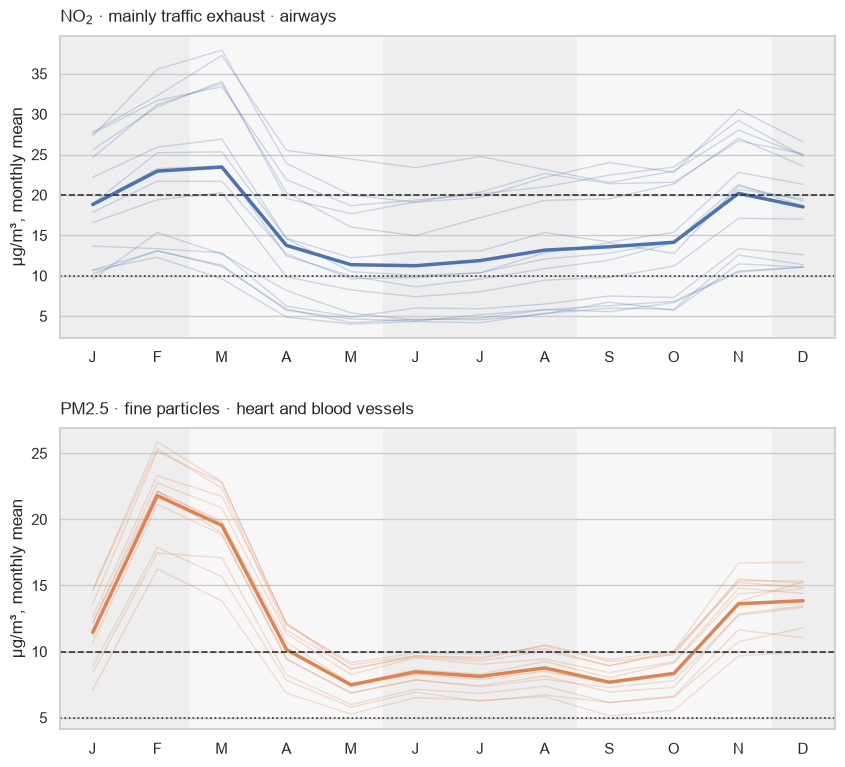

In [35]:
# Monthly mean, one line per station, one panel per pollutant.
# Alternating grey bands group the meteorological seasons without collapsing months.
SEASONS = [(12, 2), (3, 5), (6, 8), (9, 11)]
BAND = ["#eeeeee", "#f7f7f7", "#eeeeee", "#f7f7f7"]
MONTHS = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]

fig, axes = plt.subplots(2, 1, figsize=(10, 9))

for ax, core in zip(axes, ["no2", "pm2"]):
    # Bands first so the lines draw over them. Winter wraps the year, so it is split.
    for (start, end), shade in zip(SEASONS, BAND):
        if start > end:
            ax.axvspan(0.5, end + 0.5, color=shade, zorder=0)
            ax.axvspan(start - 0.5, 12.5, color=shade, zorder=0)
        else:
            ax.axvspan(start - 0.5, end + 0.5, color=shade, zorder=0)

    g = mon[mon["core"] == core]
    for st, s in g.groupby("station"):
        ax.plot(s["month"], s["mean"], color=COLOUR[core], alpha=0.25, lw=1)
    ax.plot(g.groupby("month")["mean"].mean(), color=COLOUR[core], lw=2.5)

    ax.axhline(LIMIT[core], color="#333333", lw=1.2, ls="--")
    ax.axhline(WHO[core], color="#333333", lw=1.2, ls=":")
    ax.set_title(LABEL[core], pad=10, loc="left")
    ax.set_ylabel("µg/m³, monthly mean")
    ax.set_xlim(0.5, 12.5)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(MONTHS)
    ax.grid(axis="x", visible=False)

plt.subplots_adjust(hspace=0.3)
plt.savefig(ROOT / "figures" / "03_monthly.png", dpi=150, pad_inches=0.3)

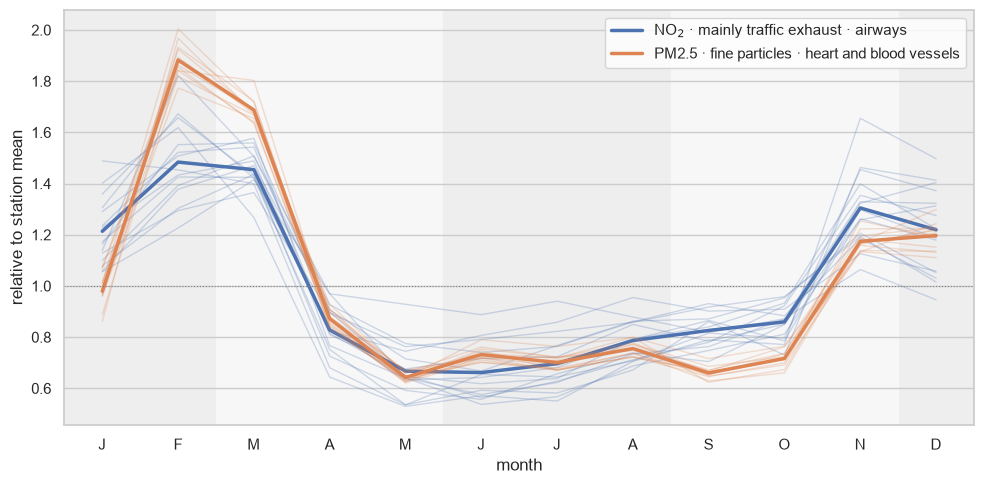

In [36]:
# Each month as a share of the station's own yearly mean.
# Same normalisation as the daily cycle in 02, so the two pollutants compare.
rel = mon.copy()
rel["rel"] = rel["mean"] / rel.groupby(["core", "station"])["mean"].transform("mean")

fig, ax = plt.subplots(figsize=(10, 5))

for (start, end), shade in zip(SEASONS, BAND):
    if start > end:
        ax.axvspan(0.5, end + 0.5, color=shade, zorder=0)
        ax.axvspan(start - 0.5, 12.5, color=shade, zorder=0)
    else:
        ax.axvspan(start - 0.5, end + 0.5, color=shade, zorder=0)

for core in ["no2", "pm2"]:
    g = rel[rel["core"] == core]
    for st, s in g.groupby("station"):
        ax.plot(s["month"], s["rel"], color=COLOUR[core], alpha=0.25, lw=1,
                label="_nolegend_")
    ax.plot(g.groupby("month")["rel"].mean(), color=COLOUR[core], lw=2.5,
            label=LABEL[core])

ax.axhline(1, color="grey", lw=0.8, ls=":")
ax.set_xlabel("month")
ax.set_xlim(0.5, 12.5)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTHS)
ax.set_ylabel("relative to station mean")
ax.grid(axis="x", visible=False)
ax.legend()

plt.tight_layout()
plt.savefig(ROOT / "figures" / "03_seasonal_shape.png", dpi=150)

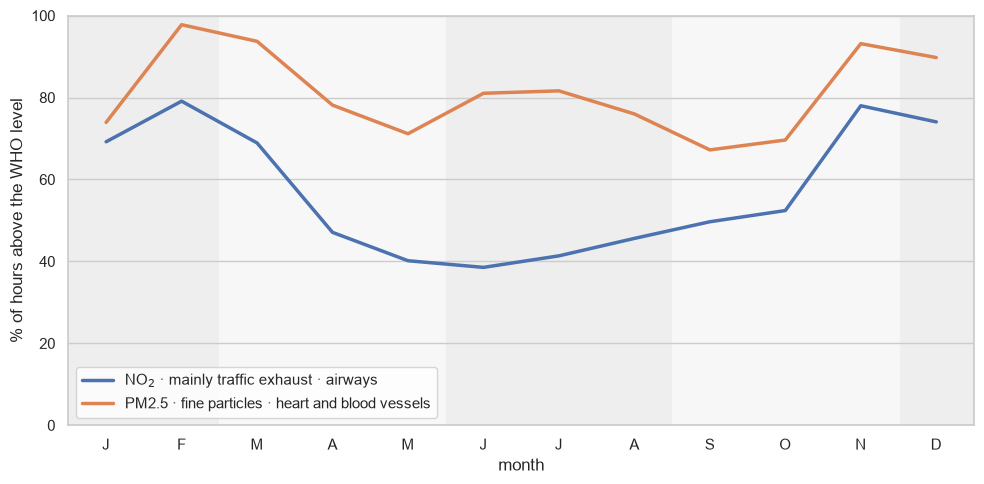

In [37]:
# Hours above the WHO level per month, summed across stations.
# Counts exposure, not shape. The WHO level is an annual mean, used here as a
# yardstick for how much of each month sits above it.
exceed = df.copy()
exceed["month"] = exceed["datetime"].dt.month
exceed["above"] = exceed["value"] > exceed["core"].map(WHO)

cnt = exceed.groupby(["core", "month"])["above"].mean().mul(100).unstack(0)

fig, ax = plt.subplots(figsize=(10, 5))

for (start, end), shade in zip(SEASONS, BAND):
    if start > end:
        ax.axvspan(0.5, end + 0.5, color=shade, zorder=0)
        ax.axvspan(start - 0.5, 12.5, color=shade, zorder=0)
    else:
        ax.axvspan(start - 0.5, end + 0.5, color=shade, zorder=0)

for core in ["no2", "pm2"]:
    ax.plot(cnt.index, cnt[core], color=COLOUR[core], lw=2.5, label=LABEL[core])

ax.set_xlabel("month")
ax.set_xlim(0.5, 12.5)
ax.set_ylim(0, 100)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(MONTHS)
ax.set_ylabel("% of hours above the WHO level")
ax.grid(axis="x", visible=False)
ax.legend()

plt.tight_layout()
plt.savefig(ROOT / "figures" / "03_hours_above.png", dpi=150)

In [38]:
# The fireworks flag covers 31 Dec 18:00 to 1 Jan 06:00, so it touches both months.
# If excluding it shifts the monthly mean, the seasonal figures need a second version.
for m, name in [(1, "Jan"), (12, "Dec")]:
    sub = df[df["datetime"].dt.month == m]
    for core in ["no2", "pm2"]:
        g = sub[sub["core"] == core]
        print(name, core,
              "| with", round(g["value"].mean(), 2),
              "| without", round(g[~g["fireworks"]]["value"].mean(), 2))

Jan no2 | with 18.85 | without 18.88
Jan pm2 | with 11.47 | without 11.18
Dec no2 | with 18.56 | without 18.55
Dec pm2 | with 13.85 | without 13.66


In [39]:
# Days above the 24-hour PM2.5 levels, per station.
# Real limits with defined allowances: EU 2030 25 µg/m³ max 18 days,
# WHO 15 µg/m³ max 3–4 days. Daily means, so days dropped in 01 are excluded.
daily = (df.groupby(["core", "station", df["datetime"].dt.date])["value"]
           .mean().rename("mean").reset_index()
           .rename(columns={"datetime": "date"}))

pm = daily[daily["core"] == "pm2"]
days = pm.groupby("station")["mean"].agg(
    above_eu=lambda s: (s > 25).sum(),
    above_who=lambda s: (s > 15).sum(),
)
days.index = days.index.map(NAME)
print(days.sort_values("above_who", ascending=False))

                                       above_eu  above_who
station                                                   
Mariendorfer Damm, Mariendorf                30        107
Frankfurter Allee, Friedrichshain            33        106
Silbersteinstr., Neukölln                    30        104
Karl-Marx-Str., Neukölln                     27        102
Leipziger Str., Mitte                        27         91
Nansenstr., Neukölln                         20         86
Brückenstr., Mitte                           20         85
Schildhornstr., Steglitz                     22         76
Amrumer Str., Wedding                        18         70
Buch, Pankow                                 11         48
Friedrichshagen, Treptow-Köpenick            11         45
Grunewald, Charlottenburg-Wilmersdorf         9         34


In [40]:
# H2 claims winter peaks at every station. idxmax gives each station's highest month.
# All peaks in 1, 2 or 12 means H2 holds in full.
peak = mon.loc[mon.groupby(["core", "station"])["mean"].idxmax()]
print(peak.groupby(["core", "month"]).size())

core  month
no2   1         1
      2         4
      3         9
      11        1
pm2   2        12
dtype: int64


Share of hours above the WHO level, % per month
core   NO2  PM2.5
Jan   69.0   74.0
Feb   79.0   98.0
Mar   69.0   94.0
Apr   47.0   78.0
May   40.0   71.0
Jun   39.0   81.0
Jul   41.0   82.0
Aug   46.0   76.0
Sep   50.0   67.0
Oct   52.0   70.0
Nov   78.0   93.0
Dec   74.0   90.0


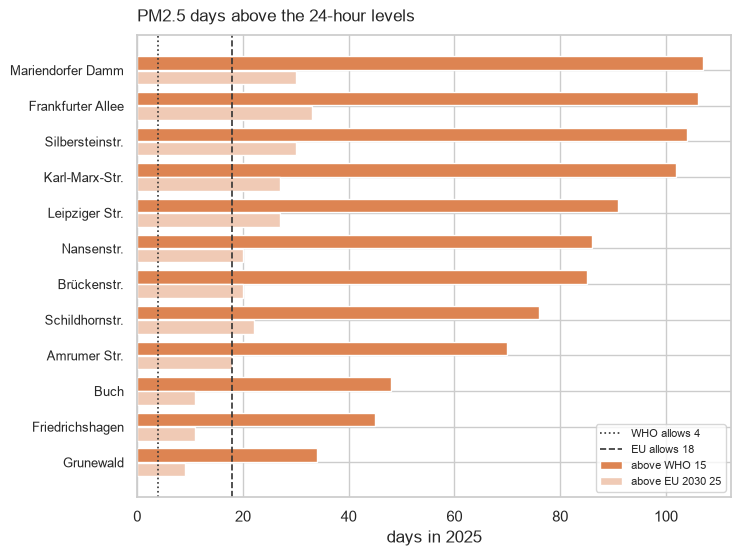

In [43]:
# Days above the 24-hour PM2.5 levels, per station, against what the rules allow.
# EU 2030: 25 µg/m³, max 18 days. WHO: 15 µg/m³, max 3–4 days.
# These are real 24-hour limits, not a yardstick.
ALLOWED = {"eu": 18, "who": 4}

g = days.sort_values("above_who", ascending=False)
y = range(len(g))

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh([i - 0.2 for i in y], g["above_who"], height=0.38,
        color=COLOUR["pm2"], label="above WHO 15")
ax.barh([i + 0.2 for i in y], g["above_eu"], height=0.38,
        color=PALE["pm2"], label="above EU 2030 25")

ax.axvline(ALLOWED["who"], color="#333333", lw=1.2, ls=":",
           label=f"WHO allows {ALLOWED['who']}")
ax.axvline(ALLOWED["eu"], color="#333333", lw=1.2, ls="--",
           label=f"EU allows {ALLOWED['eu']}")

ax.set_yticks(list(y))
ax.set_yticklabels([n.split(", ")[0] for n in g.index], fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("days in 2025")
ax.set_title("PM2.5 days above the 24-hour levels", pad=10, loc="left")
ax.legend(loc="lower right", fontsize=8)

plt.subplots_adjust(left=0.30, right=0.96)
plt.savefig(ROOT / "figures" / "03_days_above.png", dpi=150, pad_inches=0.3)

# Share of hours above the WHO level, per month and pollutant, in %.
# The WHO level is a yearly average, used here as a yardstick for single hours.
out = cnt.round(0).rename(columns={"no2": "NO2", "pm2": "PM2.5"})
out.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
             "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
print("Share of hours above the WHO level, % per month")
print(out)

## Findings

- H2 holds for PM2.5: all 12 stations peak in February
- H2 fails for NO₂ as stated. Peaks fall in March at 9 of 15 stations, February
  at 4, January at 1, November at 1. March is spring under the Dec–Feb definition
- The March NO₂ peak matches the extreme hours found in 01, all of which fell on
  7, 10 and 20 March
- Share of hours above the WHO level, NO₂: 79 % in February, 38 % in June
- Share of hours above the WHO level, PM2.5: 97 % in February, 67 % in September
- PM2.5 is above the WHO level in about two thirds of hours or more, every month.
  The WHO level is a yearly average, used here as a yardstick for single hours
- The seasonal swing is larger for NO₂ than for PM2.5
- Days above the 24-hour PM2.5 levels: 8 of 12 stations exceed the EU 2030
  allowance of 18 days above 25 µg/m³. All 12 exceed WHO's 3 to 4 days above
  15 µg/m³, with 34 to 107 days
- Excluding the New Year fireworks lowers January PM2.5 from 11.5 to 11.2 µg/m³.
  The seasonal pattern does not change

## Open

- The March NO₂ peak coincides with exceptional weather. DWD recorded 20 of 31
  days under high pressure, the second sunniest March since 1951 and one of the
  driest since 1881, with the north-east receiving about 9 l/m² of rain
  ([DWD](https://www.dwd.de/DE/presse/pressemitteilungen/DE/2025/20250331_pm_maerz_news.html)).
  High pressure makes air sink and settle, which stops pollution mixing upward.
  Clear nights cool the ground and trap a cold layer underneath warmer air. Weak
  winds leave it in place. Emissions stay where they are released
- One year of data. The March result may not recur, and testing that needs
  several years or DWD weather data joined to the series
- February was also dry and high-pressure dominated, yet PM2.5 peaked there and
  NO₂ in March. Heating is a plausible reason, February being colder, but this
  data cannot show it